# 03 — Choix du modèle

Le notebook 02 a fixé les entrées. Ce notebook cherche le meilleur modèle, en deux temps :

- **Partie 1, sur l'énoncé seul** : quel *type* de modèle prédit le mieux les tags, à entrée égale ?
- **Partie 2, sur toutes les entrées retenues** : comment les combiner (concaténation, stacking ou MLP) ?

L'évaluation finale du modèle retenu sur le test, son analyse d'erreurs et la comparaison au LLM sont au notebook 04.

## Partie 1 — Trois modèles sur l'énoncé

| # | Modèle | Entrée | Ce qui est appris |
|---|---|---|---|
| 1 | **Regex** | description (+ code) | une liste de mots-clés par tag |
| 2 | **Régression logistique** | embedding Sentence-BERT de la description (768 dim.) | 8 × 769 poids |
| 3 | **MLP** | embedding Sentence-BERT de la description | ~200 000 poids (1 couche cachée) |

**Protocole commun**
1. Données et split fixés au notebook 01 (train 3 383 / val 725 / test 726).
2. Hyperparamètres choisis en **validation croisée 5 folds sur train + val**, critère **Macro-AP** (indépendant du seuil).
   Exception : la regex ne produit pas de probabilités, sa grille est évaluée en Macro-F1 sur val.
3. Entraînement final sur train, **seuil de décision par tag réglé sur val**.
4. **Une seule évaluation sur test**, jamais utilisé avant.

In [1]:
import itertools
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from iterstrat.ml_stratifiers import (
    MultilabelStratifiedKFold,
    MultilabelStratifiedShuffleSplit,
)
from sentence_transformers import SentenceTransformer
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    hamming_loss,
    jaccard_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 140)

/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1118 11:07:31.378000 85305 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Paramètres

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks_prod" else Path.cwd()
DATA_PATH = ROOT / "data" / "processed" / "clean.parquet"
EMBEDDINGS_PATH = ROOT / "data" / "embeddings" / "all-mpnet-base-v2__prob_desc_description.npz"  # calculé au notebook 02

TAGS = ["math", "graphs", "strings", "number theory", "trees", "geometry", "games", "probabilities"]
SEED = 42
N_FOLDS = 5
N_BOOTSTRAP = 1000
THRESHOLD_GRID = np.arange(0.05, 0.96, 0.01)

# Même tokenisation du code qu'au notebook 02
CODE_TOKEN_PATTERN = r"[A-Za-z_][A-Za-z0-9_]+|\d{2,}"
CODE_STOP_WORDS = [
    "False", "None", "True", "and", "as", "assert", "async", "await", "break", "class", "continue", "def", "del",
    "elif", "else", "except", "finally", "for", "from", "global", "if", "import", "in", "is", "lambda", "nonlocal",
    "not", "or", "pass", "raise", "return", "try", "while", "with", "yield",
    "sys", "stdin", "stdout", "readline", "input", "raw_input", "print", "write", "flush", "os", "io", "self",
]  # fmt: skip

## Données

In [3]:
df = pd.read_parquet(DATA_PATH)
Y = np.array([[tag in tags for tag in TAGS] for tags in df["tags"]], dtype=int)

cache = np.load(EMBEDDINGS_PATH)
assert np.array_equal(cache["sample_id"], df.index), "cache d'embeddings non aligné : relancer le notebook 02"
E = cache["embeddings"]

split = df["split"].to_numpy()
train, val, test, dev = split == "train", split == "val", split == "test", split != "test"
train_df, val_df, test_df = df[train], df[val], df[test]
Y_train, Y_val, Y_test, Y_dev = Y[train], Y[val], Y[test], Y[dev]

pd.DataFrame({s: Y[split == s].mean(axis=0) for s in ("train", "val", "test")}, index=TAGS).style.format("{:.1%}")

,train,val,test
math,28.5%,28.4%,28.5%
graphs,11.0%,10.9%,11.0%
strings,8.5%,8.4%,8.4%
number theory,7.0%,6.9%,7.0%
trees,6.4%,6.3%,6.3%
geometry,3.4%,3.3%,3.3%
games,2.1%,2.1%,2.1%
probabilities,1.9%,1.8%,1.9%


## Outils d'évaluation

- **Métriques globales** : Micro-F1 (chaque prédiction compte autant, dominé par `math`), **Macro-F1** (moyenne des
  F1 par tag : chaque tag compte autant, c'est la métrique principale), Hamming loss (part de cases mal prédites),
  Jaccard moyen par exemple.
- **Seuil par tag** : un modèle donne une probabilité par tag ; le seuil 0,5 n'est pas adapté à des tags rares. Pour
  chaque tag, on choisit sur val le seuil qui maximise le F1.
- **Folds** : les mêmes 5 folds stratifiés (sur train + val) pour tous les modèles.

In [4]:
def global_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "jaccard": jaccard_score(y_true, y_pred, average="samples", zero_division=1),  # aucun tag vrai ni prédit = parfait
    }


def tune_thresholds(y_true: np.ndarray, proba: np.ndarray) -> np.ndarray:
    """Pour chaque tag, le seuil de THRESHOLD_GRID qui maximise le F1."""
    thresholds = []
    for k in range(y_true.shape[1]):
        f1s = [f1_score(y_true[:, k], proba[:, k] >= t, zero_division=0) for t in THRESHOLD_GRID]
        thresholds.append(THRESHOLD_GRID[np.argmax(f1s)])
    return np.array(thresholds)


def predict_with_val_thresholds(proba_val: np.ndarray, proba_test: np.ndarray) -> np.ndarray:
    return (proba_test >= tune_thresholds(Y_val, proba_val)).astype(int)


def macro_ap(y_true: np.ndarray, proba: np.ndarray) -> float:
    return average_precision_score(y_true, proba, average="macro")


folds = list(MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(dev.sum()), Y_dev))

# Résultats de toutes les versions de modèles : prédictions test et ligne du tableau final
test_predictions: dict[str, np.ndarray] = {}
results: dict[str, dict] = {}


def record(name: str, family: str, config: str, pred_test: np.ndarray, cv_ap: float = np.nan) -> None:
    test_predictions[name] = pred_test
    results[name] = {"famille": family, "configuration": config, "cv_macro_ap": cv_ap, **global_metrics(Y_test, pred_test)}


def show(family: str) -> pd.DataFrame:
    table = pd.DataFrame(results).T
    return table[table["famille"] == family].drop(columns="famille").infer_objects().round(3)

## 1. Modèle 1 — Regex (plancher sans apprentissage statistique)

Un tag est prédit dès qu'un de ses mots-clés apparaît dans l'exercice.

**Référence** : des mots-clés écrits à la main, sans regarder les données.

In [5]:
MANUAL_PATTERNS = {
    "math": r"\b(?:sum|product|divisible|modulo|equation|formula|integer)\b",
    "graphs": r"\b(?:graph|vertex|vertices|edges?|roads?|cities)\b",
    "strings": r"\b(?:strings?|substrings?|palindromes?|letters?|characters?)\b",
    "number theory": r"\b(?:primes?|gcd|lcm|divisors?|coprime|modulo)\b",
    "trees": r"\b(?:trees?|rooted|subtrees?|leaf|leaves)\b",
    "geometry": r"\b(?:polygons?|circles?|angles?|coordinates|triangles?|segments?)\b",
    "games": r"\b(?:game|players?|winner|wins|optimally)\b",
    "probabilities": r"\b(?:probability|expected|expectation|random)\b",
}


def regex_predict(texts: pd.Series, patterns: dict[str, str]) -> np.ndarray:
    """Matrice (n x 8) : 1 si le texte contient un mot-clé du tag."""
    return np.column_stack([texts.str.contains(patterns[tag], flags=re.IGNORECASE).to_numpy() for tag in TAGS]).astype(int)


record("regex manuelle", "regex", "mots-clés écrits à la main", regex_predict(test_df["text_clean"], MANUAL_PATTERNS))

**Version apprise** : les mots-clés de chaque tag sont tirés de la **TF-IDF par tag** du notebook 02, calculée sur le
**train uniquement** :
- les `k_desc` meilleurs termes de la description lemmatisée et les `k_code` meilleurs tokens du code ;
- un terme n'est gardé que s'il est au moins `min_lift` fois plus marqué pour le tag que pour les exercices sans tag
  cible (élimine les termes génériques) ;
- pour chaque tag, on décide sur val si les mots-clés du code s'ajoutent à ceux de la description.

In [6]:
NO_TAG = "(aucun tag cible)"
groups = {tag: Y_train[:, k] == 1 for k, tag in enumerate(TAGS)}
groups[NO_TAG] = Y_train.sum(axis=1) == 0


def tag_tfidf(texts: pd.Series, **vectorizer_args) -> pd.DataFrame:
    """Même score qu'au notebook 02 : part des exercices du tag contenant le terme × IDF globale."""
    vectorizer = CountVectorizer(min_df=5, binary=True, **vectorizer_args)
    presence = vectorizer.fit_transform(texts)
    idf = np.log(presence.shape[0] / presence.sum(axis=0).A1)
    scores = {name: presence[mask].mean(axis=0).A1 * idf for name, mask in groups.items()}
    return pd.DataFrame(scores, index=vectorizer.get_feature_names_out()).T


def select_keywords(scores: pd.DataFrame, k: int, min_lift: float) -> dict[str, list[str]]:
    """Les k meilleurs termes de chaque tag, parmi ceux min_lift fois plus marqués que pour « aucun tag »."""
    reference = scores.loc[NO_TAG]
    return {tag: scores.loc[tag][scores.loc[tag] > min_lift * reference].nlargest(k).index.tolist() for tag in TAGS}


def to_patterns(keywords: dict[str, list[str]]) -> dict[str, str]:
    # (?!) ne correspond à rien : un tag sans mot-clé n'est jamais prédit
    return {tag: r"\b(?:" + "|".join(map(re.escape, words)) + r")\b" if words else r"(?!)" for tag, words in keywords.items()}


def fit_regex(k_desc: int, k_code: int, min_lift: float) -> dict:
    """Mots-clés appris sur train, puis choix par tag (sur val) d'utiliser ou non ceux du code."""
    model = {
        "desc_words": select_keywords(desc_scores, k_desc, min_lift),
        "code_words": select_keywords(code_scores, k_code, min_lift=5.0),
        "use_code": np.zeros(len(TAGS), dtype=bool),
    }
    desc_only = predict_regex(model, val_df)
    model["use_code"][:] = True
    desc_or_code = predict_regex(model, val_df)
    model["use_code"] = np.array(
        [f1_score(Y_val[:, k], desc_or_code[:, k], zero_division=0) > f1_score(Y_val[:, k], desc_only[:, k], zero_division=0) for k in range(len(TAGS))]
    )
    return model


def predict_regex(model: dict, data: pd.DataFrame) -> np.ndarray:
    from_desc = regex_predict(data["text_lemma"], to_patterns(model["desc_words"]))
    from_code = regex_predict(data["source_code"], to_patterns(model["code_words"]))
    return np.where(model["use_code"], np.maximum(from_desc, from_code), from_desc)


# Les scores ne dépendent pas des hyperparamètres : calculés une seule fois
desc_scores = tag_tfidf(train_df["text_lemma"], stop_words="english", ngram_range=(1, 2))
code_scores = tag_tfidf(train_df["source_code"], token_pattern=CODE_TOKEN_PATTERN, lowercase=False, stop_words=CODE_STOP_WORDS)

grid = []
for min_lift, k_desc, k_code in itertools.product((2, 3, 5, 10), (2, 3, 5, 10), (1, 2, 3, 5, 10)):
    model = fit_regex(k_desc, k_code, min_lift)
    grid.append({"min_lift": min_lift, "k_desc": k_desc, "k_code": k_code, "val_macro_f1": global_metrics(Y_val, predict_regex(model, val_df))["macro_f1"]})
regex_grid = pd.DataFrame(grid).sort_values("val_macro_f1", ascending=False, ignore_index=True)
print(f"{len(regex_grid)} configurations testées ; les 5 meilleures :")
regex_grid.head(5).round(3)

80 configurations testées ; les 5 meilleures :


,min_lift,k_desc,k_code,val_macro_f1
0,5,2,5,0.501
1,5,2,3,0.497
2,2,2,5,0.497
3,5,2,2,0.494
4,5,2,10,0.493


In [7]:
best = regex_grid.iloc[0]
regex_model = fit_regex(int(best["k_desc"]), int(best["k_code"]), best["min_lift"])

pd.DataFrame(
    {
        "mots-clés description": {t: ", ".join(w) for t, w in regex_model["desc_words"].items()},
        "mots-clés code": {t: ", ".join(w) for t, w in regex_model["code_words"].items()},
        "code utilisé": dict(zip(TAGS, regex_model["use_code"])),
    }
)

,mots-clés description,mots-clés code,code utilisé
math,"divisible, divisor","pow, lru_cache, primes, fact, factor",True
graphs,"connected, graph","edges, node, visited, stack, popleft",True
strings,"string, letter","ord, chr, replace, 97, lower",False
number theory,"divisor, greatest","gcd, pow, prime, primes, factor",True
trees,"tree, vertex","parent, node, dfs, root, tree",False
geometry,"plane, point","x1, x2, y1, y2, points",False
games,"play optimally, optimally","Alice, Bob, odd, even, win",False
probabilities,"probability, expected","pow, random, 998244353, prob, randint",False


In [8]:
config = f"k_desc={int(best['k_desc'])}, k_code={int(best['k_code'])}, min_lift={best['min_lift']:g}"
record("regex TF-IDF", "regex", config, predict_regex(regex_model, test_df))
show("regex")

,configuration,cv_macro_ap,micro_f1,macro_f1,hamming_loss,jaccard
regex manuelle,mots-clés écrits à la main,NaN,0.459,0.482,0.12,0.417
regex TF-IDF,"k_desc=2, k_code=5, min_lift=5",NaN,0.454,0.518,0.10,0.494


## 2. Modèle 2 — Régression logistique sur les embeddings

8 régressions logistiques indépendantes (une par tag, *one-vs-rest*) : $P(\text{tag} \mid x) = \sigma(w^\top x + b)$,
avec $x$ l'embedding Sentence-BERT de la description.
- Pénalité $L_2$ de force $1/C$, `class_weight="balanced"` pour compenser la rareté des tags.
- Hyperparamètres testés en CV : `C`, et une **PCA** optionnelle pour réduire les 768 dimensions.

### 2.1 Faut-il réduire les 768 dimensions ?

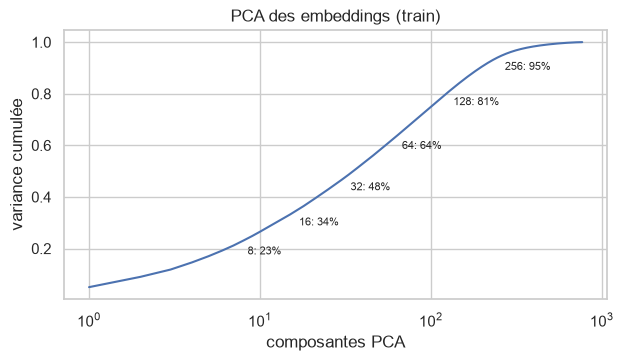

Composantes nécessaires pour 90 % de la variance : 194


In [9]:
cumulative = np.cumsum(PCA(random_state=SEED).fit(E[train]).explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative)
for k in (8, 16, 32, 64, 128, 256):
    ax.annotate(f"{k}: {cumulative[k - 1]:.0%}", (k, cumulative[k - 1]), textcoords="offset points", xytext=(3, -10), fontsize=8)
ax.set(xscale="log", xlabel="composantes PCA", ylabel="variance cumulée", title="PCA des embeddings (train)")
plt.show()
print(f"Composantes nécessaires pour 90 % de la variance : {np.searchsorted(cumulative, 0.9) + 1}")

### 2.2 Choix de la PCA et de `C` en validation croisée

`GridSearchCV` teste toutes les combinaisons sur nos 5 folds. La PCA est une étape du pipeline : elle est réapprise
dans chaque fold, sur les données d'entraînement du fold uniquement.

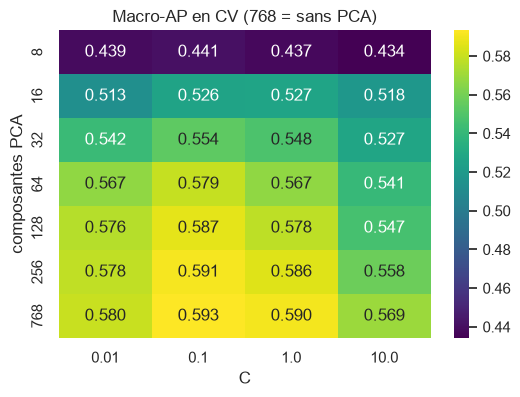

,n_components,C,cv_macro_ap
7,768,0.1,0.5933
13,256,0.1,0.5914
14,768,1.0,0.5903
12,128,0.1,0.5869
20,256,1.0,0.5858


In [10]:
def logistic(C: float = 1.0) -> OneVsRestClassifier:
    return OneVsRestClassifier(LogisticRegression(C=C, class_weight="balanced", max_iter=2000))


pipeline = Pipeline([("pca", "passthrough"), ("clf", logistic())])
param_grid = {
    "pca": ["passthrough"] + [PCA(n, random_state=SEED) for n in (8, 16, 32, 64, 128, 256)],
    "clf__estimator__C": [0.01, 0.1, 1.0, 10.0],
}
search = GridSearchCV(pipeline, param_grid, scoring="average_precision", cv=folds).fit(E[dev], Y_dev)

logreg_cv = pd.DataFrame(
    {
        "n_components": [768 if p == "passthrough" else p.n_components for p in search.cv_results_["param_pca"]],
        "C": search.cv_results_["param_clf__estimator__C"],
        "cv_macro_ap": search.cv_results_["mean_test_score"],
    }
)
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(logreg_cv.pivot(index="n_components", columns="C", values="cv_macro_ap"), annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set(title="Macro-AP en CV (768 = sans PCA)", ylabel="composantes PCA")
plt.show()
logreg_cv.sort_values("cv_macro_ap", ascending=False).head(5).round(4)

### 2.3 Entraînement final

On entraîne la configuration par défaut (`C=1`, sans PCA) et la meilleure de la CV. La même régression logistique sur
la TF-IDF de l'énoncé a été mesurée au notebook 02 (section 1) : elle fait jeu égal avec l'embedding.

In [11]:
def cv_score(params: dict) -> float:
    match = (logreg_cv["n_components"] == params["n_components"]) & (logreg_cv["C"] == params["C"])
    return logreg_cv.loc[match, "cv_macro_ap"].item()


def fit_and_predict(model, X_train, X_val, X_test) -> np.ndarray:
    model.fit(X_train, Y_train)
    return predict_with_val_thresholds(model.predict_proba(X_val), model.predict_proba(X_test))


record("logreg (C=1)", "logreg", "Sentence-BERT, sans PCA, C=1",
       fit_and_predict(logistic(1.0), E[train], E[val], E[test]), cv_score({"n_components": 768, "C": 1.0}))

best = logreg_cv.loc[logreg_cv["cv_macro_ap"].idxmax()]
n_components, C = int(best["n_components"]), best["C"]
pca = "passthrough" if n_components == 768 else PCA(n_components, random_state=SEED)
pca_label = "sans PCA" if n_components == 768 else f"PCA={n_components}"
record("logreg (meilleure CV)", "logreg", f"Sentence-BERT, {pca_label}, C={C:g}",
       fit_and_predict(Pipeline([("pca", pca), ("clf", logistic(C))]), E[train], E[val], E[test]), best["cv_macro_ap"])
show("logreg")

,configuration,cv_macro_ap,micro_f1,macro_f1,hamming_loss,jaccard
logreg (C=1),"Sentence-BERT, sans PCA, C=1",0.590,0.554,0.612,0.083,0.532
logreg (meilleure CV),"Sentence-BERT, sans PCA, C=0.1",0.593,0.536,0.585,0.094,0.469


## 3. Modèle 3 — MLP sur les embeddings

Un réseau à une couche cachée : `768 → Linear(256) → ReLU → Dropout → Linear(8)`, une sortie sigmoïde par tag
(les tags ne s'excluent pas). Il peut capter des interactions non linéaires entre dimensions de l'embedding.

**Entraînement**
- Loss `BCEWithLogitsLoss` avec `pos_weight = n_négatifs / n_positifs` par tag (équivalent de `class_weight="balanced"`).
- AdamW, batchs de 64, **early stopping** : on garde l'epoch où la loss sur un jeu d'arrêt est minimale (patience 15).
- **Le jeu d'arrêt n'est jamais le jeu évalué** : en CV, on le prend dans la partie entraînement du fold (15 %) ;
  pour le modèle final, c'est val. Sinon le score mesuré serait optimiste.

In [12]:
class MLP(nn.Module):
    def __init__(self, dropout: float, input_dim: int = 768, hidden: int = 256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(input_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, len(TAGS)))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)  # logits ; la sigmoïde est dans la loss et dans mlp_proba


def train_mlp(X, Y, X_stop, Y_stop, lr=1e-3, weight_decay=1e-4, dropout=0.3, seed=SEED, max_epochs=200, patience=15):
    """Renvoie le modèle à sa meilleure epoch (loss minimale sur X_stop) et l'historique des loss."""
    torch.manual_seed(seed)
    X, Y = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
    X_stop, Y_stop = torch.tensor(X_stop, dtype=torch.float32), torch.tensor(Y_stop, dtype=torch.float32)

    model = MLP(dropout, input_dim=X.shape[1])
    positives = Y.sum(dim=0).clamp(min=1)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=(len(Y) - positives) / positives)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    history, best_loss, best_state, best_epoch = [], float("inf"), None, 0
    for epoch in range(max_epochs):
        model.train()
        for batch in torch.randperm(len(X)).split(64):
            optimizer.zero_grad()
            loss = loss_fn(model(X[batch]), Y[batch])
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            stop_loss = loss_fn(model(X_stop), Y_stop).item()
            history.append({"epoch": epoch, "train_loss": loss_fn(model(X), Y).item(), "stop_loss": stop_loss})
        if stop_loss < best_loss:
            best_loss, best_epoch = stop_loss, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if epoch - best_epoch >= patience:
            break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


def mlp_proba(model: MLP, X: np.ndarray) -> np.ndarray:
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(X, dtype=torch.float32))).numpy()


def cv_mlp(**params) -> float:
    """Macro-AP en CV ; dans chaque fold, 15 % de la partie entraînement sert à l'early stopping."""
    X_dev, scores = E[dev], []
    for train_idx, eval_idx in folds:
        splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
        fit_pos, stop_pos = next(splitter.split(train_idx, Y_dev[train_idx]))
        fit_idx, stop_idx = train_idx[fit_pos], train_idx[stop_pos]
        model, _ = train_mlp(X_dev[fit_idx], Y_dev[fit_idx], X_dev[stop_idx], Y_dev[stop_idx], **params)
        scores.append(macro_ap(Y_dev[eval_idx], mlp_proba(model, X_dev[eval_idx])))
    return np.mean(scores)

### 3.1 Choix de `lr`, `weight_decay` et `dropout` en validation croisée

24 configurations testées en 62 s


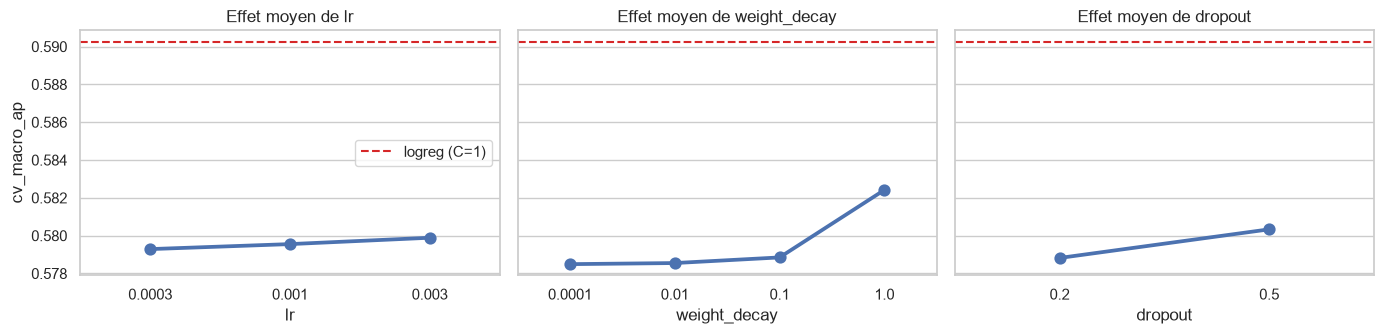

,lr,weight_decay,dropout,cv_macro_ap
0,0.003,1.0,0.5,0.5865
1,0.003,1.0,0.2,0.5863
2,0.001,1.0,0.5,0.5817
3,0.001,1.0,0.2,0.5809
4,0.003,0.1,0.5,0.5804


In [13]:
start = time.perf_counter()
mlp_grid = pd.DataFrame(
    [
        {"lr": lr, "weight_decay": wd, "dropout": dropout, "cv_macro_ap": cv_mlp(lr=lr, weight_decay=wd, dropout=dropout)}
        for lr, wd, dropout in itertools.product((3e-4, 1e-3, 3e-3), (1e-4, 1e-2, 1e-1, 1.0), (0.2, 0.5))
    ]
).sort_values("cv_macro_ap", ascending=False, ignore_index=True)
print(f"{len(mlp_grid)} configurations testées en {time.perf_counter() - start:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, param in zip(axes, ["lr", "weight_decay", "dropout"]):
    sns.pointplot(data=mlp_grid, x=param, y="cv_macro_ap", errorbar=None, ax=ax)
    ax.axhline(results["logreg (C=1)"]["cv_macro_ap"], color="tab:red", linestyle="--", label="logreg (C=1)")
    ax.set(title=f"Effet moyen de {param}")
axes[0].legend()
plt.tight_layout()
plt.show()
mlp_grid.head(5).round(4)

### 3.2 Entraînement final

Configuration par défaut et meilleure configuration de la CV ; early stopping sur val. Les courbes montrent où
l'apprentissage est arrêté.

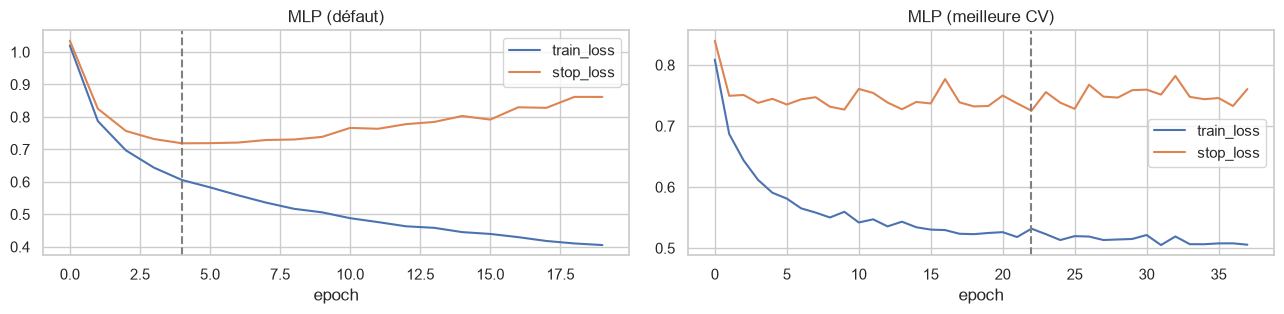

In [14]:
best = mlp_grid.iloc[0]
mlp_configs = {
    "MLP (défaut)": {"lr": 1e-3, "weight_decay": 1e-4, "dropout": 0.3},
    "MLP (meilleure CV)": {"lr": best["lr"], "weight_decay": best["weight_decay"], "dropout": best["dropout"]},
}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.3))
for ax, (name, params) in zip(axes, mlp_configs.items()):
    model, history = train_mlp(E[train], Y_train, E[val], Y_val, **params)
    pred = predict_with_val_thresholds(mlp_proba(model, E[val]), mlp_proba(model, E[test]))
    record(name, "MLP", ", ".join(f"{k}={v:g}" for k, v in params.items()), pred, cv_mlp(**params))
    history.plot(x="epoch", y=["train_loss", "stop_loss"], ax=ax, title=name)
    ax.axvline(history["stop_loss"].idxmin(), color="gray", linestyle="--")
plt.tight_layout()
plt.show()

### 3.3 Stabilité vis-à-vis de l'initialisation

La régression logistique est un problème convexe (solution unique) ; le MLP dépend de sa graine aléatoire.

In [15]:
tuned = mlp_configs["MLP (meilleure CV)"]
seed_scores = []
for seed in range(5):
    model, _ = train_mlp(E[train], Y_train, E[val], Y_val, seed=seed, **tuned)
    pred = predict_with_val_thresholds(mlp_proba(model, E[val]), mlp_proba(model, E[test]))
    seed_scores.append(global_metrics(Y_test, pred)["macro_f1"])
print(f"MLP (meilleure CV), 5 graines : Macro-F1 test {np.mean(seed_scores):.3f} ± {np.std(seed_scores):.3f} "
      f"(min {min(seed_scores):.3f}, max {max(seed_scores):.3f})")
show("MLP")

MLP (meilleure CV), 5 graines : Macro-F1 test 0.569 ± 0.013 (min 0.552, max 0.590)


,configuration,cv_macro_ap,micro_f1,macro_f1,hamming_loss,jaccard
MLP (défaut),"lr=0.001, weight_decay=0.0001, dropout=0.3",0.577,0.525,0.552,0.104,0.418
MLP (meilleure CV),"lr=0.003, weight_decay=1, dropout=0.5",0.586,0.533,0.593,0.098,0.448


## 4. Synthèse

### 4.1 Tableau récapitulatif (test, 726 exercices)

`cv_macro_ap` sert à **choisir** ; les colonnes du test servent au **constat final**.

In [16]:
summary = pd.DataFrame(results).T.infer_objects()
(
    summary.style.format(precision=3, na_rep="—")
    .highlight_max(subset=["cv_macro_ap", "micro_f1", "macro_f1", "jaccard"], color="#c6efce")
    .highlight_min(subset=["hamming_loss"], color="#c6efce")
)

,famille,configuration,cv_macro_ap,micro_f1,macro_f1,hamming_loss,jaccard
regex manuelle,regex,mots-clés écrits à la main,—,0.459,0.482,0.120,0.417
regex TF-IDF,regex,"k_desc=2, k_code=5, min_lift=5",—,0.454,0.518,0.100,0.494
logreg (C=1),logreg,"Sentence-BERT, sans PCA, C=1",0.590,0.554,0.612,0.083,0.532
logreg (meilleure CV),logreg,"Sentence-BERT, sans PCA, C=0.1",0.593,0.536,0.585,0.094,0.469
MLP (défaut),MLP,"lr=0.001, weight_decay=0.0001, dropout=0.3",0.577,0.525,0.552,0.104,0.418
MLP (meilleure CV),MLP,"lr=0.003, weight_decay=1, dropout=0.5",0.586,0.533,0.593,0.098,0.448


### 4.2 F1 par tag

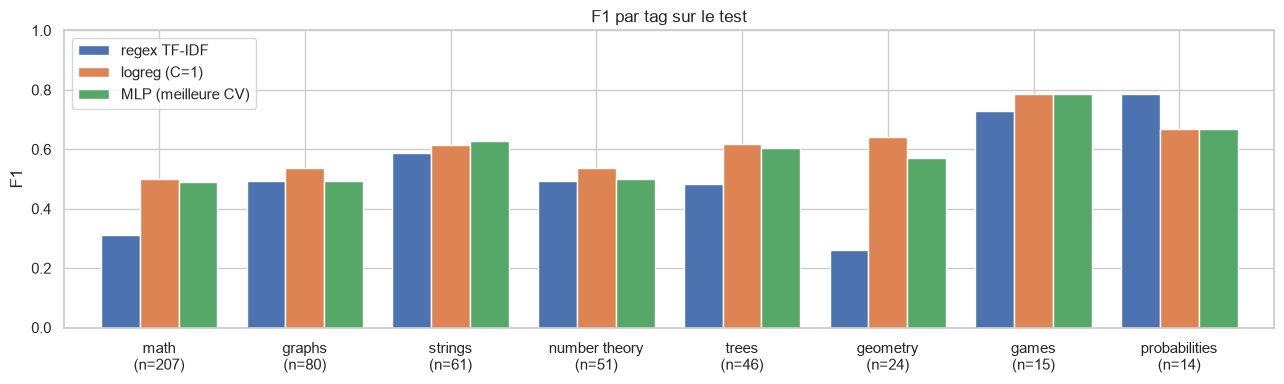

,math,graphs,strings,number theory,trees,geometry,games,probabilities
regex TF-IDF,0.31,0.49,0.59,0.49,0.48,0.26,0.73,0.79
logreg (C=1),0.50,0.54,0.61,0.54,0.62,0.64,0.79,0.67
MLP (meilleure CV),0.49,0.49,0.63,0.50,0.60,0.57,0.79,0.67


In [17]:
champions = ["regex TF-IDF", "logreg (C=1)", "MLP (meilleure CV)"]
f1_by_tag = pd.DataFrame(
    {name: precision_recall_fscore_support(Y_test, test_predictions[name], zero_division=0)[2] for name in champions}, index=TAGS
)
support = Y_test.sum(axis=0)

fig, ax = plt.subplots(figsize=(13, 4))
f1_by_tag.plot.bar(ax=ax, rot=0, width=0.8)
ax.set(title="F1 par tag sur le test", ylabel="F1", ylim=(0, 1))
ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(TAGS, support)])
plt.tight_layout()
plt.show()
f1_by_tag.T.round(2)

### 4.3 Les écarts sont-ils significatifs ?

**Bootstrap apparié** : on tire 1 000 fois 726 exercices du test avec remise, et on calcule à chaque tirage la
différence de Macro-F1 entre deux modèles **sur les mêmes exercices**. Un écart est significatif si son intervalle
de confiance à 95 % exclut 0.

In [18]:
def bootstrap_diff(pred_a: np.ndarray, pred_b: np.ndarray) -> dict[str, float]:
    rng = np.random.default_rng(SEED)
    diffs = []
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(Y_test), len(Y_test))
        diffs.append(
            f1_score(Y_test[idx], pred_a[idx], average="macro", zero_division=0)
            - f1_score(Y_test[idx], pred_b[idx], average="macro", zero_division=0)
        )
    low, high = np.percentile(diffs, [2.5, 97.5])
    return {"écart moyen": np.mean(diffs), "IC 2,5 %": low, "IC 97,5 %": high, "P(a > b)": np.mean(np.array(diffs) > 0)}


pairs = [
    ("regex TF-IDF", "regex manuelle"),
    ("logreg (C=1)", "regex TF-IDF"),
    ("logreg (C=1)", "MLP (défaut)"),
    ("logreg (C=1)", "MLP (meilleure CV)"),
]
pd.DataFrame({f"{a} − {b}": bootstrap_diff(test_predictions[a], test_predictions[b]) for a, b in pairs}).T.round(3)

,écart moyen,"IC 2,5 %","IC 97,5 %",P(a > b)
regex TF-IDF − regex manuelle,0.036,-0.001,0.073,0.972
logreg (C=1) − regex TF-IDF,0.093,0.044,0.144,1.000
logreg (C=1) − MLP (défaut),0.062,0.018,0.106,0.995
logreg (C=1) − MLP (meilleure CV),0.020,0.002,0.036,0.984


### 4.4 Latence d'inférence (contrainte : < 10 s par exemple)

Temps pour prédire un exercice, encodage Sentence-BERT compris (médiane sur 50 exercices).

In [19]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
encoder = SentenceTransformer("sentence-transformers/all-mpnet-base-v2", device=device)
logreg_model = logistic(1.0).fit(E[train], Y_train)
mlp_model, _ = train_mlp(E[train], Y_train, E[val], Y_val, **tuned)
def encode(i: int) -> np.ndarray:
    return encoder.encode([test_df["text_clean"].iloc[i]], normalize_embeddings=True)


encode(0)  # échauffement

predictors = {
    "regex TF-IDF": lambda i: predict_regex(regex_model, test_df.iloc[[i]]),
    "logreg (C=1)": lambda i: logreg_model.predict_proba(encode(i)),
    "MLP (meilleure CV)": lambda i: mlp_proba(mlp_model, encode(i)),
}
latency = {}
for name, predict in predictors.items():
    times = []
    for i in range(50):
        start = time.perf_counter()
        predict(i)
        times.append(time.perf_counter() - start)
    latency[name] = {"médiane (ms)": np.median(times) * 1000, "max (ms)": np.max(times) * 1000}
pd.DataFrame(latency).T.round(1)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14384.85it/s]

,médiane (ms),max (ms)
regex TF-IDF,0.4,2.0
logreg (C=1),15.3,33.2
MLP (meilleure CV),14.9,30.7


### 4.5 Erreurs du modèle retenu (régression logistique, C=1)

In [20]:
pred = test_predictions["logreg (C=1)"]
display(
    pd.DataFrame(
        {"faux positifs": ((pred == 1) & (Y_test == 0)).sum(axis=0), "faux négatifs": ((pred == 0) & (Y_test == 1)).sum(axis=0), "support": support},
        index=TAGS,
    )
)

for kind, tag in [("faux négatifs", "math"), ("faux positifs", "number theory")]:
    k = TAGS.index(tag)
    mask = (pred[:, k] == 0) & (Y_test[:, k] == 1) if kind == "faux négatifs" else (pred[:, k] == 1) & (Y_test[:, k] == 0)
    print(f"=== {tag} : {kind} ===")
    for sid, row in test_df[mask].head(2).iterrows():
        print(f"  [{sid}] tags={list(row['tags'])} -> {row['prob_desc_description'][:150]}...")

,faux positifs,faux négatifs,support
math,133,94,207
graphs,45,34,80
strings,25,23,61
number theory,28,22,51
trees,28,13,46
geometry,14,6,24
games,2,4,15
probabilities,8,3,14


=== math : faux négatifs ===
  [4] tags=['binary search', 'divide and conquer', 'brute force', 'math'] -> Thanos wants to destroy the avengers base, but he needs to destroy the avengers along with their base.Let we represent their base with an array, where...
  [40] tags=['number theory', 'bitmasks', 'math', 'strings'] -> You are given two strings $$$s$$$ and $$$t$$$, both consisting of exactly $$$k$$$ lowercase Latin letters, $$$s$$$ is lexicographically less than $$$t...
=== number theory : faux positifs ===
  [38] tags=['dp', 'combinatorics', 'brute force'] -> The Travelling Salesman spends a lot of time travelling so he tends to get bored. To pass time, he likes to perform operations on numbers. One such op...
  [97] tags=['dp', 'hashing', 'data structures', 'binary search', 'strings'] -> Vasya owns three big integers — $$$a, l, r$$$. Let's define a partition of $$$x$$$ such a sequence of strings $$$s_1, s_2, \dots, s_k$$$ that $$$s_1 +...


### 4.6 Conclusions

| Modèle | Verdict |
|---|---|
| **Regex** | Plancher utile : le vocabulaire appris bat le vocabulaire manuel, mais un mot-clé ne suffit pas à reconnaître une technique de résolution. |
| **Régression logistique** | **Meilleur modèle.** Nettement au-dessus de la regex, rapide et déterministe. |
| **MLP** | Pas de gain : sur ~3 400 exemples et des embeddings déjà structurés, la couche cachée ajoute surtout de la variance (voir 3.3). La meilleure configuration est la plus régularisée (`weight_decay=1`, bord de la grille) : le MLP gagne quand il se rapproche d'un modèle linéaire. |

- **La PCA n'aide pas** : l'information est répartie sur toutes les dimensions (~190 composantes pour 90 % de la
  variance) ; la régularisation $L_2$ suffit.
- **`C=1` contre la meilleure CV** : Macro-AP égales à l'écart-type près ; on garde la configuration par défaut.
- **Décision** : la régression logistique sur embeddings devient la référence. Les gains suivants viendront de
  **nouvelles entrées** (code, spécifications, notes, difficulté) plutôt que d'un classifieur plus profond → partie 2.

## 5. Partie 2 — Combiner toutes les entrées retenues

Le notebook 02 a retenu cinq sources : les embeddings de l'énoncé, de la spécification d'entrée et des notes, le code
encodé par UniXcoder, et la difficulté en tranches. La TF-IDF de l'énoncé reste candidate comme source complémentaire.
Trois façons de les combiner :

1. **Concaténation** : toutes les sources côte à côte (~3 000 colonnes standardisées), puis 8 régressions logistiques
   avec un seul `C`. C'est l'instrument « plusieurs sources » du notebook 02.
2. **Stacking** (deux niveaux) :
   - *niveau 1* : une régression logistique par source, chacune avec sa propre transformation (TF-IDF, tranches) ;
   - *niveau 2* : pour chaque tag, une régression logistique sur les **logits** des sources, qui apprend quelle source
     croire pour ce tag ;
   - le niveau 2 est entraîné sur des prédictions **out-of-fold** : chaque prédiction de niveau 1 vient d'un modèle qui
     n'a pas vu l'exemple. Sinon, le niveau 2 ferait trop confiance aux sources qui sur-apprennent.

   C'est aussi la seule des trois qui accueille simplement la TF-IDF (une matrice creuse de ~1 800 colonnes) : elle
   garde son propre modèle au lieu d'être mélangée aux embeddings.
3. **MLP multimodal** : le MLP de la partie 1, sur les sources concaténées. Sa couche cachée peut capter des
   interactions entre sources (un énoncé sur des nombres et `gcd` dans le code), ce que les deux autres ne font pas.

**Protocole** : les mêmes 5 folds sur train + val, critère Macro-AP. Le test n'est pas utilisé : il sert au notebook 04.

**Règle de choix, fixée avant de lancer** : on retient la meilleure Macro-AP en CV. Le MLP, plus coûteux et plus
variable, ne l'emporte que s'il dépasse les modèles linéaires d'au moins un écart-type entre folds (≈ 0,027).

In [21]:
EMBEDDINGS_DIR = ROOT / "data" / "embeddings"
EMBEDDING_FILES = {  # calculés au notebook 02
    "description": "all-mpnet-base-v2__prob_desc_description.npz",
    "input_spec": "all-mpnet-base-v2__prob_desc_input_spec.npz",
    "notes": "all-mpnet-base-v2__prob_desc_notes.npz",
    "code": "unixcoder-base__source_code.npz",
}
DENSE_BLOCKS = ["description", "input_spec", "notes", "code", "difficulty"]
DIFFICULTY_BINS = 5


def load_embeddings(filename: str) -> np.ndarray:
    cache = np.load(EMBEDDINGS_DIR / filename)
    assert np.array_equal(cache["sample_id"], df.index), f"{filename} non aligné : relancer le notebook 02"
    return cache["embeddings"]


blocks = {name: load_embeddings(filename) for name, filename in EMBEDDING_FILES.items()}
blocks["difficulty"] = df[["difficulty"]].to_numpy(dtype=float)
blocks["tfidf_desc"] = df["text_lemma"].to_numpy()
blocks["tfidf_code"] = df["source_code"].to_numpy()
dev_blocks = {name: block[dev] for name, block in blocks.items()}
pd.Series({name: block.shape[1] if block.ndim == 2 else "texte → TF-IDF" for name, block in blocks.items()}, name="colonnes").to_frame().T

,description,input_spec,notes,code,difficulty,tfidf_desc,tfidf_code
colonnes,768,768,768,768,1,texte → TF-IDF,texte → TF-IDF


In [22]:
class DifficultyEncoder(BaseEstimator, TransformerMixin):
    """One-hot de la difficulté : tranches de quantiles (apprises au fit) + une colonne « inconnue » (NaN, -1)."""

    def __init__(self, n_bins: int = DIFFICULTY_BINS):
        self.n_bins = n_bins

    def fit(self, X: np.ndarray, y=None) -> "DifficultyEncoder":
        values = X[:, 0]
        known = values[values > 0]  # NaN > 0 est faux : NaN et -1 sont exclus
        self.edges_ = np.quantile(known, np.linspace(0, 1, self.n_bins + 1)[1:-1])
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        values = X[:, 0]
        column = np.where(values > 0, np.digitize(np.nan_to_num(values), self.edges_), self.n_bins)
        return np.eye(self.n_bins + 1)[column]


def concat_features(model, sources: dict) -> np.ndarray:
    """Sources denses côte à côte ; la difficulté passe par l'encodeur appris au fit du modèle."""
    return np.hstack([model.difficulty_.transform(sources[n]) if n == "difficulty" else sources[n] for n in model.names])


class ConcatModel(BaseEstimator):
    """Sources denses concaténées → standardisation → 8 régressions logistiques."""

    def __init__(self, names: list[str], C: float):
        self.names, self.C = names, C

    def fit(self, sources: dict, Y: np.ndarray) -> "ConcatModel":
        self.difficulty_ = DifficultyEncoder().fit(sources["difficulty"])
        self.model_ = make_pipeline(StandardScaler(), logistic(self.C)).fit(concat_features(self, sources), Y)
        return self

    def predict_proba(self, sources: dict) -> np.ndarray:
        return self.model_.predict_proba(concat_features(self, sources))


def block_model(name: str):
    """Modèle de niveau 1 d'une source ; sa transformation (tranches, vocabulaire) est apprise au fit."""
    if name == "difficulty":
        return make_pipeline(DifficultyEncoder(), logistic())
    if name == "tfidf_desc":
        return make_pipeline(TfidfVectorizer(stop_words="english", min_df=10, sublinear_tf=True), logistic(1.0))
    if name == "tfidf_code":
        vectorizer = TfidfVectorizer(token_pattern=CODE_TOKEN_PATTERN, lowercase=False, stop_words=CODE_STOP_WORDS, min_df=5, sublinear_tf=True)
        return make_pipeline(vectorizer, logistic(0.3))
    return logistic()  # embeddings


def logit(p: np.ndarray) -> np.ndarray:
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


class StackingModel(BaseEstimator):
    """Niveau 1 : un modèle par source. Niveau 2 : par tag, une régression logistique sur les logits out-of-fold."""

    def __init__(self, names: list[str]):
        self.names = names

    def fit(self, sources: dict, Y: np.ndarray) -> "StackingModel":
        inner_folds = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
        # oof[:, b, k] : probabilité out-of-fold du tag k selon la source b
        oof = np.stack(
            [cross_val_predict(block_model(n), sources[n], Y, cv=inner_folds, method="predict_proba") for n in self.names], axis=1
        )
        self.block_models_ = {n: block_model(n).fit(sources[n], Y) for n in self.names}
        self.meta_models_ = [LogisticRegression(class_weight="balanced").fit(logit(oof[:, :, k]), Y[:, k]) for k in range(Y.shape[1])]
        return self

    def predict_proba(self, sources: dict) -> np.ndarray:
        probas = np.stack([self.block_models_[n].predict_proba(sources[n]) for n in self.names], axis=1)
        return np.column_stack([meta.predict_proba(logit(probas[:, :, k]))[:, 1] for k, meta in enumerate(self.meta_models_)])


class MultimodalMLP(BaseEstimator):
    """Sources denses concaténées → standardisation → moyenne de `n_seeds` MLP de la partie 1."""

    def __init__(self, names: list[str], lr: float = 3e-3, weight_decay: float = 1.0, dropout: float = 0.5, n_seeds: int = 5):
        self.names, self.lr, self.weight_decay, self.dropout, self.n_seeds = names, lr, weight_decay, dropout, n_seeds

    def fit(self, sources: dict, Y: np.ndarray) -> "MultimodalMLP":
        self.difficulty_ = DifficultyEncoder().fit(sources["difficulty"])
        self.scaler_ = StandardScaler().fit(concat_features(self, sources))
        X = self.scaler_.transform(concat_features(self, sources))
        # 15 % de l'entraînement pour l'early stopping, jamais le jeu évalué
        splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
        fit_idx, stop_idx = next(splitter.split(X, Y))
        params = {"lr": self.lr, "weight_decay": self.weight_decay, "dropout": self.dropout}
        self.nets_ = [
            train_mlp(X[fit_idx], Y[fit_idx], X[stop_idx], Y[stop_idx], seed=seed, **params)[0] for seed in range(self.n_seeds)
        ]
        return self

    def predict_proba(self, sources: dict) -> np.ndarray:
        X = self.scaler_.transform(concat_features(self, sources))
        return np.mean([mlp_proba(net, X) for net in self.nets_], axis=0)


def cv_blocks(model) -> pd.Series:
    """Macro-AP en CV sur les mêmes folds que la partie 1 ; `clone` repart d'un modèle vierge à chaque fold."""
    scores = []
    for train_idx, eval_idx in folds:
        fitted = clone(model).fit({n: b[train_idx] for n, b in dev_blocks.items()}, Y_dev[train_idx])
        scores.append(macro_ap(Y_dev[eval_idx], fitted.predict_proba({n: b[eval_idx] for n, b in dev_blocks.items()})))
    return pd.Series({"cv_macro_ap": np.mean(scores), "cv_std": np.std(scores)})

### 5.1 Concaténation : réglage de `C`

Avec ~3 000 colonnes standardisées pour ~3 300 exemples par fold, il faut une régularisation bien plus forte que pour
une source seule.

In [23]:
concat_grid = pd.DataFrame({C: cv_blocks(ConcatModel(DENSE_BLOCKS, C)) for C in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1)}).T.rename_axis("C")
BEST_CONCAT_C = concat_grid["cv_macro_ap"].idxmax()
print("C retenu :", BEST_CONCAT_C)
concat_grid.round(4)

C retenu : 0.001


,cv_macro_ap,cv_std
C,,
0.0001,0.6467,0.0350
0.0003,0.6576,0.0327
0.0010,0.6609,0.0298
0.0030,0.6544,0.0277
0.0100,0.6379,0.0242
0.0300,0.6238,0.0206
0.1000,0.6118,0.0211


### 5.2 Stacking : faut-il ajouter les TF-IDF ?

Le stacking permet d'ajouter une source TF-IDF avec son propre modèle. On teste la TF-IDF de l'énoncé (candidate au
notebook 02) et, pour vérification, celle du code (écartée au notebook 02).

In [24]:
stacking_variants = {
    "stacking (sources denses)": DENSE_BLOCKS,
    "stacking + tfidf_desc": DENSE_BLOCKS + ["tfidf_desc"],
    "stacking + tfidf_code": DENSE_BLOCKS + ["tfidf_code"],
    "stacking + tfidf_desc + tfidf_code": DENSE_BLOCKS + ["tfidf_desc", "tfidf_code"],
}
stacking_grid = pd.DataFrame({label: cv_blocks(StackingModel(names)) for label, names in stacking_variants.items()}).T
stacking_grid.round(4)

,cv_macro_ap,cv_std
stacking (sources denses),0.6583,0.0263
stacking + tfidf_desc,0.6714,0.0276
stacking + tfidf_code,0.6571,0.0214
stacking + tfidf_desc + tfidf_code,0.6683,0.0251


### 5.3 MLP multimodal

Mêmes réglages que le meilleur MLP de la partie 1 (`lr=3e-3`, `dropout=0.5`), avec deux changements :
- **moyenne de 5 graines** : on entraîne 5 réseaux identiques sauf leur graine aléatoire (poids de départ, ordre des
  exemples) et on moyenne leurs probabilités, car un seul réseau varie de ±0,013 de Macro-F1 selon sa graine (3.3) ;
- **`weight_decay`** varie seul, car son optimum était au bord de la grille en partie 1.

In [25]:
start = time.perf_counter()
mlp_grid = pd.DataFrame({wd: cv_blocks(MultimodalMLP(DENSE_BLOCKS, weight_decay=wd)) for wd in (0.3, 1.0, 3.0)}).T.rename_axis("weight_decay")
BEST_MLP_WD = mlp_grid["cv_macro_ap"].idxmax()
single_seed = cv_blocks(MultimodalMLP(DENSE_BLOCKS, weight_decay=BEST_MLP_WD, n_seeds=1))
print(f"MLP multimodal en {time.perf_counter() - start:.0f} s ; weight_decay retenu : {BEST_MLP_WD}")
print(f"Une seule graine : {single_seed['cv_macro_ap']:.4f} ; moyenne de 5 graines : {mlp_grid.loc[BEST_MLP_WD, 'cv_macro_ap']:.4f}")
mlp_grid.round(4)

MLP multimodal en 59 s ; weight_decay retenu : 3.0
Une seule graine : 0.6388 ; moyenne de 5 graines : 0.6584


,cv_macro_ap,cv_std
weight_decay,,
0.3,0.6278,0.0347
1.0,0.6561,0.0326
3.0,0.6584,0.0335


### 5.4 Comparaison et choix

,cv_macro_ap,cv_std
"régression logistique, énoncé seul (partie 1)",0.5903,NaN
stacking + tfidf_code,0.6571,0.0214
stacking (sources denses),0.6583,0.0263
"MLP multimodal (weight_decay=3, 5 graines)",0.6584,0.0335
concaténation (C=0.001),0.6609,0.0298
stacking + tfidf_desc + tfidf_code,0.6683,0.0251
stacking + tfidf_desc,0.6714,0.0276


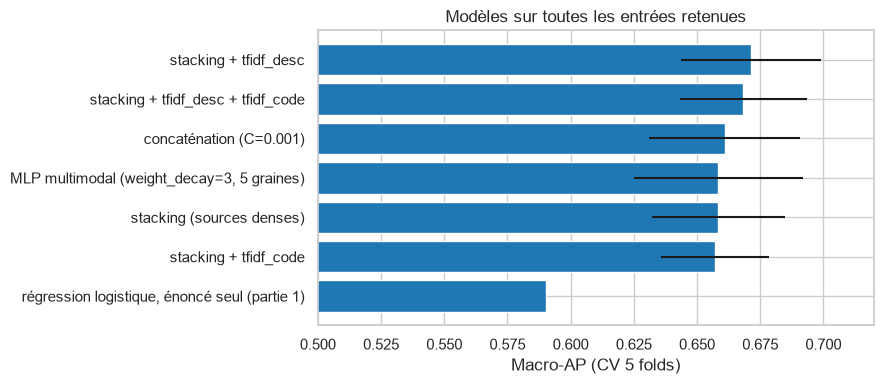

In [26]:
comparison = pd.DataFrame(
    {
        "régression logistique, énoncé seul (partie 1)": pd.Series({"cv_macro_ap": results["logreg (C=1)"]["cv_macro_ap"], "cv_std": np.nan}),
        f"concaténation (C={BEST_CONCAT_C:g})": concat_grid.loc[BEST_CONCAT_C],
        f"MLP multimodal (weight_decay={BEST_MLP_WD:g}, 5 graines)": mlp_grid.loc[BEST_MLP_WD],
        **{label: stacking_grid.loc[label] for label in stacking_variants},
    }
).T.sort_values("cv_macro_ap")
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(comparison.index, comparison["cv_macro_ap"], xerr=comparison["cv_std"].fillna(0), color="tab:blue")
ax.set(xlim=(0.5, 0.72), xlabel="Macro-AP (CV 5 folds)", title="Modèles sur toutes les entrées retenues")
plt.tight_layout()
plt.show()

### Décision

- **Toutes les combinaisons multimodales dépassent nettement l'énoncé seul** (≈ 0,66 contre 0,59) : comme l'annonçait
  la partie 1, le gain vient des nouvelles entrées.
- **Le MLP multimodal ne dépasse pas les modèles linéaires** : il est à égalité avec le stacking des sources denses et
  sous la concaténation. La moyenne des graines l'aide nettement, et son meilleur réglage est encore le plus régularisé.
  La règle de choix n'est pas remplie : il n'est pas retenu.
- **Le stacking avec la TF-IDF de l'énoncé obtient la meilleure Macro-AP.** La TF-IDF du code n'apporte rien, ce qui
  confirme son rejet au notebook 02. L'écart avec la concaténation reste dans l'écart-type ; le stacking garde deux
  avantages : il accueille la TF-IDF, et ses poids de niveau 2 disent quelle source décide pour quel tag (notebook 04).

**Modèle retenu** : stacking des embeddings (énoncé, spécification, notes, code), de la difficulté et de la TF-IDF de
l'énoncé. C'est le modèle de `src/` et de `configs/stacking.yaml`. Le notebook 04 l'évalue sur le test.